In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.metrics import f1_score , precision_score , recall_score , accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

In [2]:
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
columns = [
'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
'Insulin', 'BMI', 'DiabetesPedigree', 'Age', 'Outcome'
]

In [3]:
df = pd.read_csv(url , names = columns)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.isnull().sum()

Pregnancies         0
Glucose             0
BloodPressure       0
SkinThickness       0
Insulin             0
BMI                 0
DiabetesPedigree    0
Age                 0
Outcome             0
dtype: int64

In [5]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Pregnancies       768 non-null    int64  
 1   Glucose           768 non-null    int64  
 2   BloodPressure     768 non-null    int64  
 3   SkinThickness     768 non-null    int64  
 4   Insulin           768 non-null    int64  
 5   BMI               768 non-null    float64
 6   DiabetesPedigree  768 non-null    float64
 7   Age               768 non-null    int64  
 8   Outcome           768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
x = df.drop('Outcome' , axis=1)
y=df['Outcome']

In [9]:
x_train , x_test , y_train , y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [10]:
x_train.shape

(614, 8)

In [11]:
x_test.shape

(154, 8)

In [12]:
y_train.shape

(614,)

In [13]:
y_test.shape

(154,)

In [15]:
models = {
    'LogisticRegression' : Pipeline([
        ('scaler' , StandardScaler()),
        ('lr' , LogisticRegression(max_iter=1000))
    ]),
    'RandomForest' : RandomForestClassifier(
    n_estimators = 100,
    random_state=42,
    ),
    'gradientBoosting' : GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [16]:
from tqdm import tqdm
results = []
for name , model in tqdm(models.items()):
    model.fit(x_train , y_train)
    y_pred = model.predict(x_test)

    results.append([
        name,
        accuracy_score(y_test,y_pred),
        f1_score(y_test,y_pred),
        precision_score(y_test,y_pred),
        recall_score(y_test,y_pred)
    ])

100%|████████████████████████████████████████████| 3/3 [00:00<00:00,  3.89it/s]


In [17]:
columns = ['Model Name' , 'Accuracy' , 'f1' , 'Precision' , 'Recall']

In [23]:
analysis = pd.DataFrame(results , columns=columns)
analysis = analysis.round(4)

In [24]:
analysis

,Model Name,Accuracy,f1,Precision,Recall
0,LogisticRegression,0.7532,0.6607,0.6491,0.6727
1,RandomForest,0.7208,0.6126,0.6071,0.6182
2,gradientBoosting,0.7468,0.6549,0.6379,0.6727


In [26]:
analysis = analysis.set_index('Model Name')

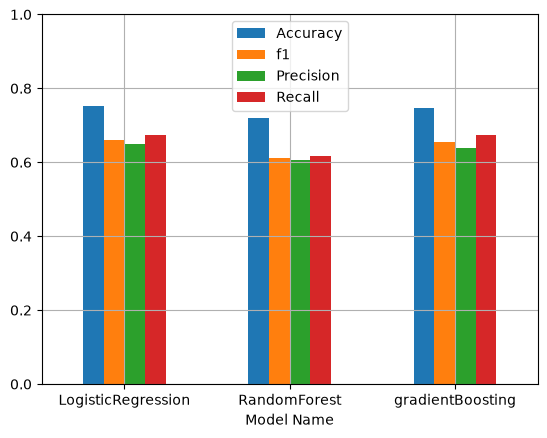

In [32]:
analysis.plot(kind =  'bar' , ylim=(0,1))
plt.xticks(rotation=0)
plt.grid(True)